In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from collections import Counter

I0000 00:00:1793482648.657353  180611 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793482648.658148  180611 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793482648.701861  180611 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793482650.371513  180611 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
(train_ds, info) = tfds.load(
    'tf_flowers',
    split='train',
    as_supervised=True,
    with_info=True
)

E0000 00:00:1793482655.599935  180611 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



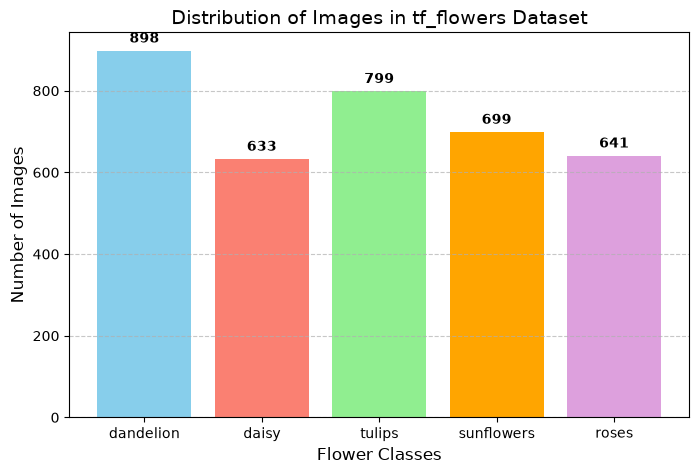

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Collect all the labels from your training dataset
labels = []
for image, label in train_ds:
  labels.append(label.numpy())

# 2. Get the human-readable class names from the 'info' object
class_names = info.features['label'].names

# 3. Count how many images belong to each class
unique_labels, counts = np.unique(labels, return_counts=True)

# 4. Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(
    [class_names[i] for i in unique_labels],
    counts,
    color=['skyblue', 'salmon', 'lightgreen', 'orange', 'plum'],
)

plt.xlabel('Flower Classes', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.title('Distribution of Images in tf_flowers Dataset', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the exact number on top of each bar
for i, count in enumerate(counts):
  plt.text(i, count + 20, str(count), ha='center', fontsize=10, fontweight='bold')

plt.show()


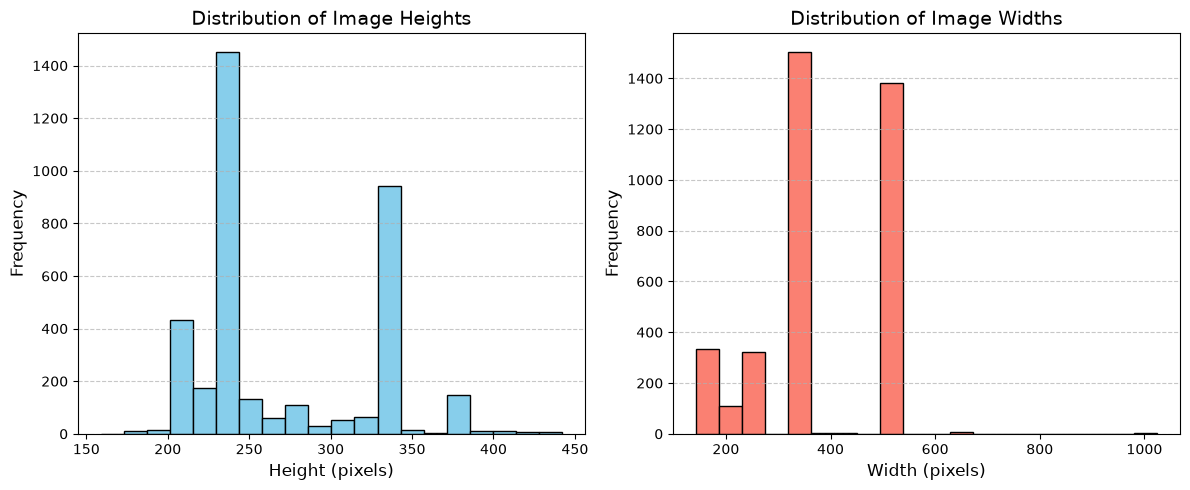

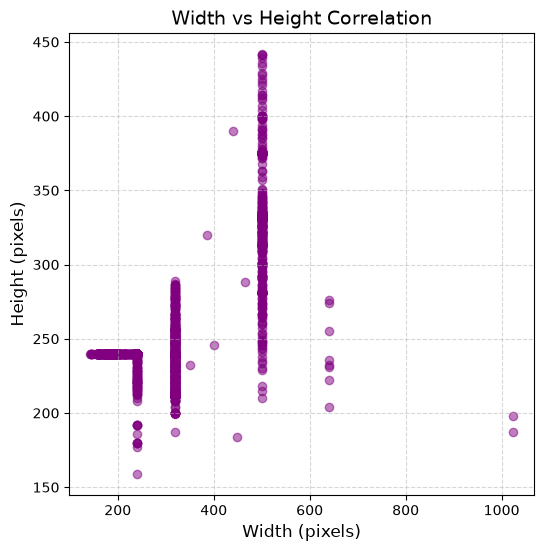

In [8]:
import matplotlib.pyplot as plt
import numpy as np

heights = []
widths = []

# 1. Iterate through the dataset and extract the shape of each image
for image, label in train_ds:
  shape = image.shape  # shape is a tuple: (height, width, channels)
  heights.append(shape[0])
  widths.append(shape[1])

# 2. Plot Histograms for Height and Width
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Height distribution
axes[0].hist(heights, bins=20, color='skyblue', edgecolor='black')
axes[0].set_title('Distribution of Image Heights', fontsize=14)
axes[0].set_xlabel('Height (pixels)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Width distribution
axes[1].hist(widths, bins=20, color='salmon', edgecolor='black')
axes[1].set_title('Distribution of Image Widths', fontsize=14)
axes[1].set_xlabel('Width (pixels)', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 3. Optional: Scatter plot to see Width vs Height relationships
plt.figure(figsize=(6, 6))
plt.scatter(widths, heights, alpha=0.5, color='purple')
plt.title('Width vs Height Correlation', fontsize=14)
plt.xlabel('Width (pixels)', fontsize=12)
plt.ylabel('Height (pixels)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [9]:
class_names = info.features['label'].names

print(class_names)  # Print the class names of the dataset

['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


In [10]:
selected_classes = ['daisy' ,  'roses', 'tulips']

In [14]:
images_by_class = {
    class_name: []
    for class_name in selected_classes
}

In [15]:
for image, label in train_ds:

    # Convert label into a Python integer
    label = int(label.numpy())

    # Get the corresponding class name
    class_name = class_names[label]

    # Keep only the required classes
    if class_name in selected_classes:

        # Resize image to 32x32
        image = tf.image.resize(
            image,
            [150, 150]
        )

        # Convert image into NumPy array
        image = image.numpy()

        # Store image in the corresponding class
        images_by_class[class_name].append(image)

In [17]:
# Number of images per class
N_IMAGES = 600

# Fixed random seed
rng = np.random.default_rng(42)

X_list = []
y_list = []

# Assign numerical labels
class_to_label = {
    'daisy': 0,
    'roses': 1,
    'tulips': 2
}

for class_name in selected_classes:

    # Convert images into NumPy array
    class_images = np.array(
        images_by_class[class_name],
        dtype=np.float32
    )

    # Check availability
    assert len(class_images) >= N_IMAGES, (
        f"Not enough images for {class_name}"
    )

    # Randomly select 300 images
    indices = rng.choice(
        len(class_images),
        size=N_IMAGES,
        replace=False
    )

    selected_images = class_images[indices]

    # Store images
    X_list.append(selected_images)

    # Store corresponding labels
    y_list.append(
        np.full(
            N_IMAGES,
            class_to_label[class_name]
        )
    )

# Combine all classes
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)

Images shape: (1800, 150, 150, 3)
Labels shape: (1800,)


In [18]:
X = X.astype(np.float32) / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [19]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [20]:
class_labels = ['Daisy', 'Rose', 'Tulip']

distribution = pd.DataFrame(
    {
        'Train': np.bincount(y_train, minlength=3),
        'Validation': np.bincount(y_val, minlength=3),
        'Test': np.bincount(y_test, minlength=3)
    },
    index=class_labels
)

distribution['Total'] = distribution.sum(axis=1)

print(distribution)

       Train  Validation  Test  Total
Daisy    360         120   120    600
Rose     360         120   120    600
Tulip    360         120   120    600


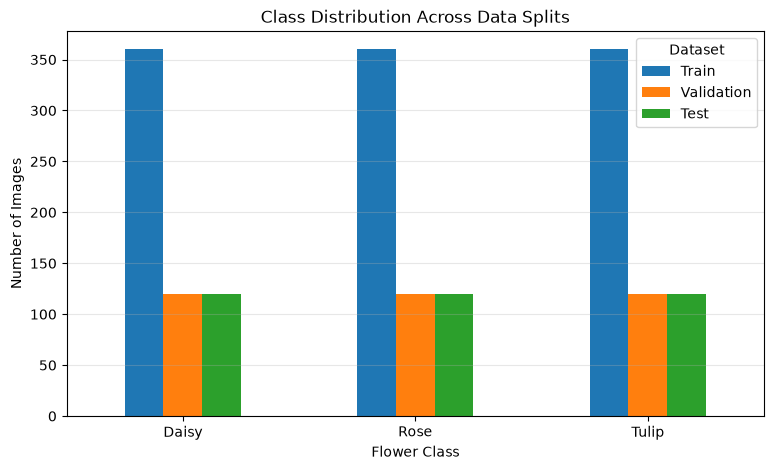

In [21]:
distribution[['Train', 'Validation', 'Test']].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Class Distribution Across Data Splits')
plt.xlabel('Flower Class')
plt.ylabel('Number of Images')
plt.xticks(rotation=0)
plt.legend(title='Dataset')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [22]:
np.savez_compressed(
    'tf_flowers_prepared.npz',

    X_train=X_train,
    y_train=y_train,

    X_val=X_val,
    y_val=y_val,

    X_test=X_test,
    y_test=y_test,

    class_names=np.array(class_labels)
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!
